##Data Visualization With Matplotlib

#Session 12

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

1.Download a sample sales dataset (for example, from Kaggle or use a small CSV you create) with columns like product, category, date, and sales amount. Load it into a Pandas DataFrame and display the first 5 rows to verify the data.

In [3]:
data = {
    "Product": ["Laptop", "Mobile", "Mouse", "Keyboard", "Monitor"],
    "Category": ["Electronics", "Electronics", "Accessories", "Accessories", "Electronics"],
    "Date": ["2026-11-01", "2026-11-02", "2026-11-03", "2026-11-04", "2026-11-05"],
    "SalesAmount": [55000, 25000, 800, 1500, 12000]
}
df = pd.DataFrame(data)
df.to_csv("sales_data.csv", index=False)

df = pd.read_csv("sales_data.csv", parse_dates=["Date"])
print(df.head())


    Product     Category       Date  SalesAmount
0    Laptop  Electronics 2026-11-01        55000
1    Mobile  Electronics 2026-11-02        25000
2     Mouse  Accessories 2026-11-03          800
3  Keyboard  Accessories 2026-11-04         1500
4   Monitor  Electronics 2026-11-05        12000


2.Using Matplotlib, create a bar chart that shows total sales for each product category (like 'Electronics', 'Clothing', 'Groceries'), similar to how Flipkart or Myntra might track category performance.

Category
Clothing        6800
Electronics    95000
Groceries       5200
Name: SalesAmount, dtype: int64


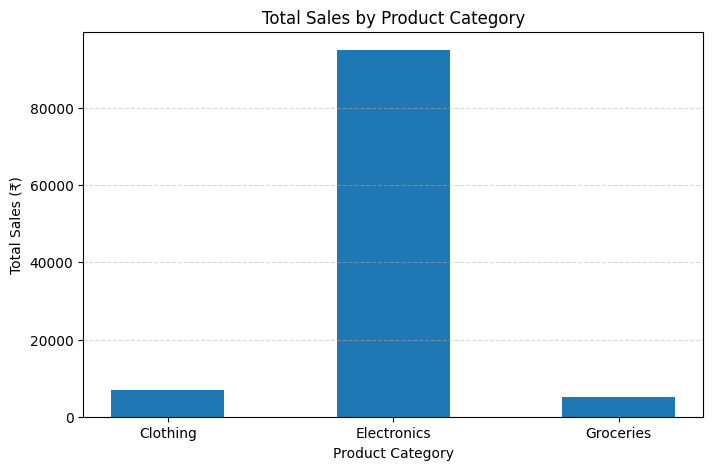

In [5]:
data = {
    "Product": ["Laptop", "Mobile", "Shirt", "Jeans", "Rice", "Oil","Monitor", "T-shirt", "Sugar"],
    "Category": ["Electronics", "Electronics", "Clothing","Clothing", "Groceries", "Groceries","Electronics", "Clothing", "Groceries"],
    "SalesAmount": [50000, 30000, 2000, 3000, 1500, 2500,15000, 1800, 1200]
}

df = pd.DataFrame(data)

# Calculate total sales category-wise
category_sales = df.groupby("Category")["SalesAmount"].sum()
print(category_sales)

plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values, width=0.5)
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


3.Plot a line chart to visualize monthly sales trends over a year, using the date column to group sales by month. Add a title and axis labels to make the chart presentation-ready.

In [8]:
monthly_sales = df.groupby(df["Date"].dt.month)["SalesAmount"].sum()
print(monthly_sales)

Date
1     25000
2     30000
3     12000
4      8000
5     15000
6     18000
7     40000
8     10000
9     22000
10    14000
11     9000
12    50000
Name: SalesAmount, dtype: int64


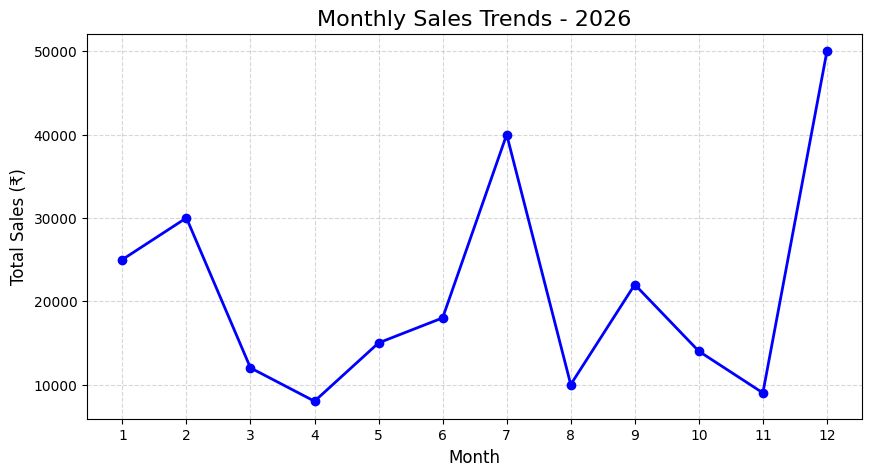

In [6]:
data = {
    "Product": ["Laptop", "Mobile", "Shirt", "Rice", "Mouse", "Jeans","Monitor", "Oil", "Keyboard", "T-shirt", "Sugar", "Mobile"],
    "Category": ["Electronics", "Electronics", "Clothing", "Groceries","Electronics", "Clothing", "Electronics", "Groceries","Electronics", "Clothing", "Groceries", "Electronics"],
    "Date": ["2026-01-15", "2026-02-10", "2026-03-12", "2026-04-05","2026-05-20", "2026-06-15", "2026-07-10", "2026-08-18","2026-09-12", "2026-10-08", "2026-11-15", "2026-12-20"],
    "SalesAmount": [25000, 30000, 12000, 8000, 15000, 18000,40000, 10000, 22000, 14000, 9000, 50000]
}
df = pd.DataFrame(data)

# Convert Date column into datetime
df["Date"] = pd.to_datetime(df["Date"])

# Group sales by month
monthly_sales = df.groupby(df["Date"].dt.month)["SalesAmount"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values,marker="o", color="blue", linewidth=2)
plt.title("Monthly Sales Trends - 2026", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales (₹)", fontsize=12)
plt.xticks(range(1, 13))
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


4.Create a histogram to show the distribution of order amounts (sales values), highlighting how many small vs. large purchases happen — like analyzing order size patterns on Zomato or Swiggy.<br><br><em><strong>Hint:</strong> Use plt.hist() and set bins to 10 for a clear distribution.</em>

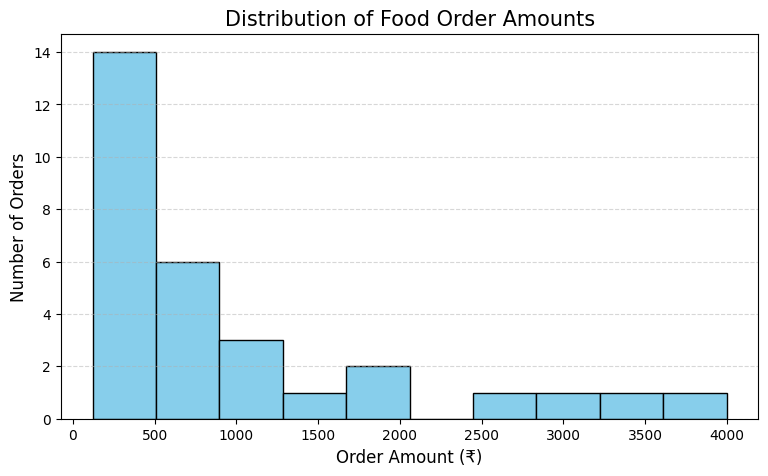

In [11]:
data = {
    "OrderAmount": [120, 150, 180, 200, 220, 250, 280, 300,
                    320, 350, 380, 400, 450, 500, 550, 600,
                    650, 700, 750, 800, 900, 1000, 1200, 1500,
                    1800, 2000, 2500, 3000, 3500, 4000]
}
df = pd.DataFrame(data)

plt.figure(figsize=(9, 5))
plt.hist(df["OrderAmount"], bins=10, edgecolor="black",color="skyblue")
plt.title("Distribution of Food Order Amounts", fontsize=15)
plt.xlabel("Order Amount (₹)", fontsize=12)
plt.ylabel("Number of Orders", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


5.Add value annotations to your category bar chart to display the exact sales amount above each bar, then export the chart as a PNG image file named 'category_sales_kpi.png'.

In [ ]:
data = {
    "Product": ["Laptop", "Mobile", "Shirt", "Jeans", "Rice","Oil", "Monitor", "T-shirt", "Sugar"],
    "Category": ["Electronics", "Electronics", "Clothing","Clothing", "Groceries", "Groceries","Electronics", "Clothing", "Groceries"],
    "SalesAmount": [50000, 30000, 2000, 3000, 1500,2500, 15000, 1800, 1200]
}
df = pd.DataFrame(data)

# Calculate category-wise total sales
category_sales = df.groupby("Category")["SalesAmount"].sum()

plt.figure(figsize=(8, 5))
bars = plt.bar(category_sales.index,category_sales.values,width=0.5,color="skyblue",edgecolor="black")

# Add value annotations
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2,height,f"₹{height:,.0f}",ha="center",va="bottom",fontsize=11)

# Add title and labels
plt.title("Total Sales by Product Category", fontsize=15)
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
# Save chart as PN
plt.savefig("category_sales_kpi.png",dpi=150,bbox_inches="tight")
plt.show()
